In [2]:
import matplotlib.pyplot as plt
import numpy as np
import re
import pandas as pd

In [3]:
input_output = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/256_inputs_outputs - sheet 1.csv')

In [4]:
input_output

,sample,output 0,output 1,output 2,z,fit,stop time 0,stop time 1,stop time 2,error 1,error 2,error 3,chem_species.max_seg_length,chem_species.seg_split_length,chem_species.max_seg_radius,chem_species.splitting_probability,chem_species.fusion_probability,chem_species.max_fusion_separation,cell_force.fungi_boundary_width
0,1,True,True,False,False,False,500000,500000,500000,no fuse,NaN,NaN,0.00379,0.00305,0.000330,0.13,0.00577,0.000405,0.000052
1,2,True,True,True,True,False,417600,417600,345600,NaN,NaN,NaN,0.00185,0.00157,0.000170,0.29,0.01355,0.000611,0.000107
2,7,False,True,True,False,False,432000,288000,288000,NaN,NaN,NaN,0.00235,0.00173,0.000243,0.26,0.01377,0.000884,0.000069
3,27,False,True,True,False,False,500000,388800,500000,NaN,NaN,NaN,0.00276,0.00226,0.000204,0.30,0.00556,0.000520,0.000120
4,30,True,True,True,False,False,475200,475200,475200,NaN,NaN,NaN,0.00308,0.00268,0.000131,0.27,0.00704,0.000376,0.000058
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,245,True,True,True,True,True,500000,500000,500000,NaN,NaN,NaN,0.00456,0.00405,0.000222,0.11,0.00783,0.000879,0.000090
252,246,True,True,True,True,True,500000,500000,500000,NaN,NaN,NaN,0.00305,0.00258,0.000278,0.26,0.01004,0.000523,0.000145
253,248,True,True,True,True,True,500000,500000,500000,NaN,NaN,NaN,0.00400,0.00364,0.000357,0.23,0.00612,0.000729,0.000106
254,250,True,True,True,True,True,500000,500000,500000,NaN,NaN,NaN,0.00237,0.00194,0.000360,0.12,0.00700,0.000417,0.000143


In [5]:
no_fuse = input_output[(input_output['error 1'] == 'no fuse') | (input_output['error 2'] == 'no fuse') | (input_output['error 3'] == 'no fuse')]

In [6]:
fit = input_output[input_output['fit'] == True]

In [7]:
no_fuse_n = no_fuse['sample'].to_list()
fit_n = fit['sample'].to_list()

In [18]:
params = ['max_l', 'split_l', 'max_r', 's_p', 'f_p', 'f_separation', 'W_A', 'split_r']
param_names = ['chem_species.max_seg_length = ', 'chem_species.seg_split_length = ',
               'chem_species.max_seg_radius = ', 'chem_species.splitting_probability = ',
               'chem_species.fusion_probability = ', 'chem_species.max_fusion_separation = ',
               'cell_force.fungi_boundary_width = '] 
bad_params = {}
good_params = {}

In [19]:
inputs_256 = pd.DataFrame(columns=['sample', 'chem_species.max_seg_length', 'chem_species.seg_split_length',
               'chem_species.max_seg_radius', 'chem_species.splitting_probability',
               'chem_species.fusion_probability', 'chem_species.max_fusion_separation',
               'cell_force.fungi_boundary_width', 'split_ratio'])

In [20]:
for n in range(0, 256):
    input_filepath = '/Users/laurenyan/bmxfungi_surrogate/256_inputs/input_fungi_' + str(n)
    params_n = [n]
    for name in param_names:
        with open(input_filepath) as input_file:
            for line in input_file:
                if line.startswith(name):
                    params_n.append(re.findall(r"-?\d+\.?\d*(?:[Ee][+-]?\d+)?", line)[0]) 
    params_n.append(float(params_n[1]) / float(params_n[2]))
    if n in no_fuse_n:
        bad_params[n] = params_n
    if n in fit_n:
        good_params[n] = params_n
    inputs_256.loc[len(inputs_256)] = params_n

inputs_256 = inputs_256.set_index('sample')

In [21]:
inputs_256.to_csv('256_outputs', index = True)

In [22]:
inputs_256

,chem_species.max_seg_length,chem_species.seg_split_length,chem_species.max_seg_radius,chem_species.splitting_probability,chem_species.fusion_probability,chem_species.max_fusion_separation,cell_force.fungi_boundary_width,split_ratio
sample,,,,,,,,
0,37.74e-4,33.22e-4,2.12e-4,0.29,0.01251,8.35e-4,1.35e-4,1.136063
1,37.94e-4,30.53e-4,3.3e-4,0.13,0.00577,4.05e-4,0.52e-4,1.242712
2,18.47e-4,15.69e-4,1.7e-4,0.29,0.01355,6.11e-4,1.07e-4,1.177183
3,32.61e-4,26.63e-4,2.82e-4,0.16,0.01055,7.61e-4,0.97e-4,1.224559
4,52.08e-4,48.24e-4,2.18e-4,0.2,0.00778,5.54e-4,1.43e-4,1.079602
...,...,...,...,...,...,...,...,...
251,26.9e-4,19.96e-4,2.48e-4,0.25,0.00905,5.67e-4,0.53e-4,1.347695
252,46.85e-4,43.92e-4,2.52e-4,0.19,0.01183,8.1e-4,1.08e-4,1.066712
253,52.17e-4,45.43e-4,3.35e-4,0.17,0.0108,6.85e-4,0.7e-4,1.148360


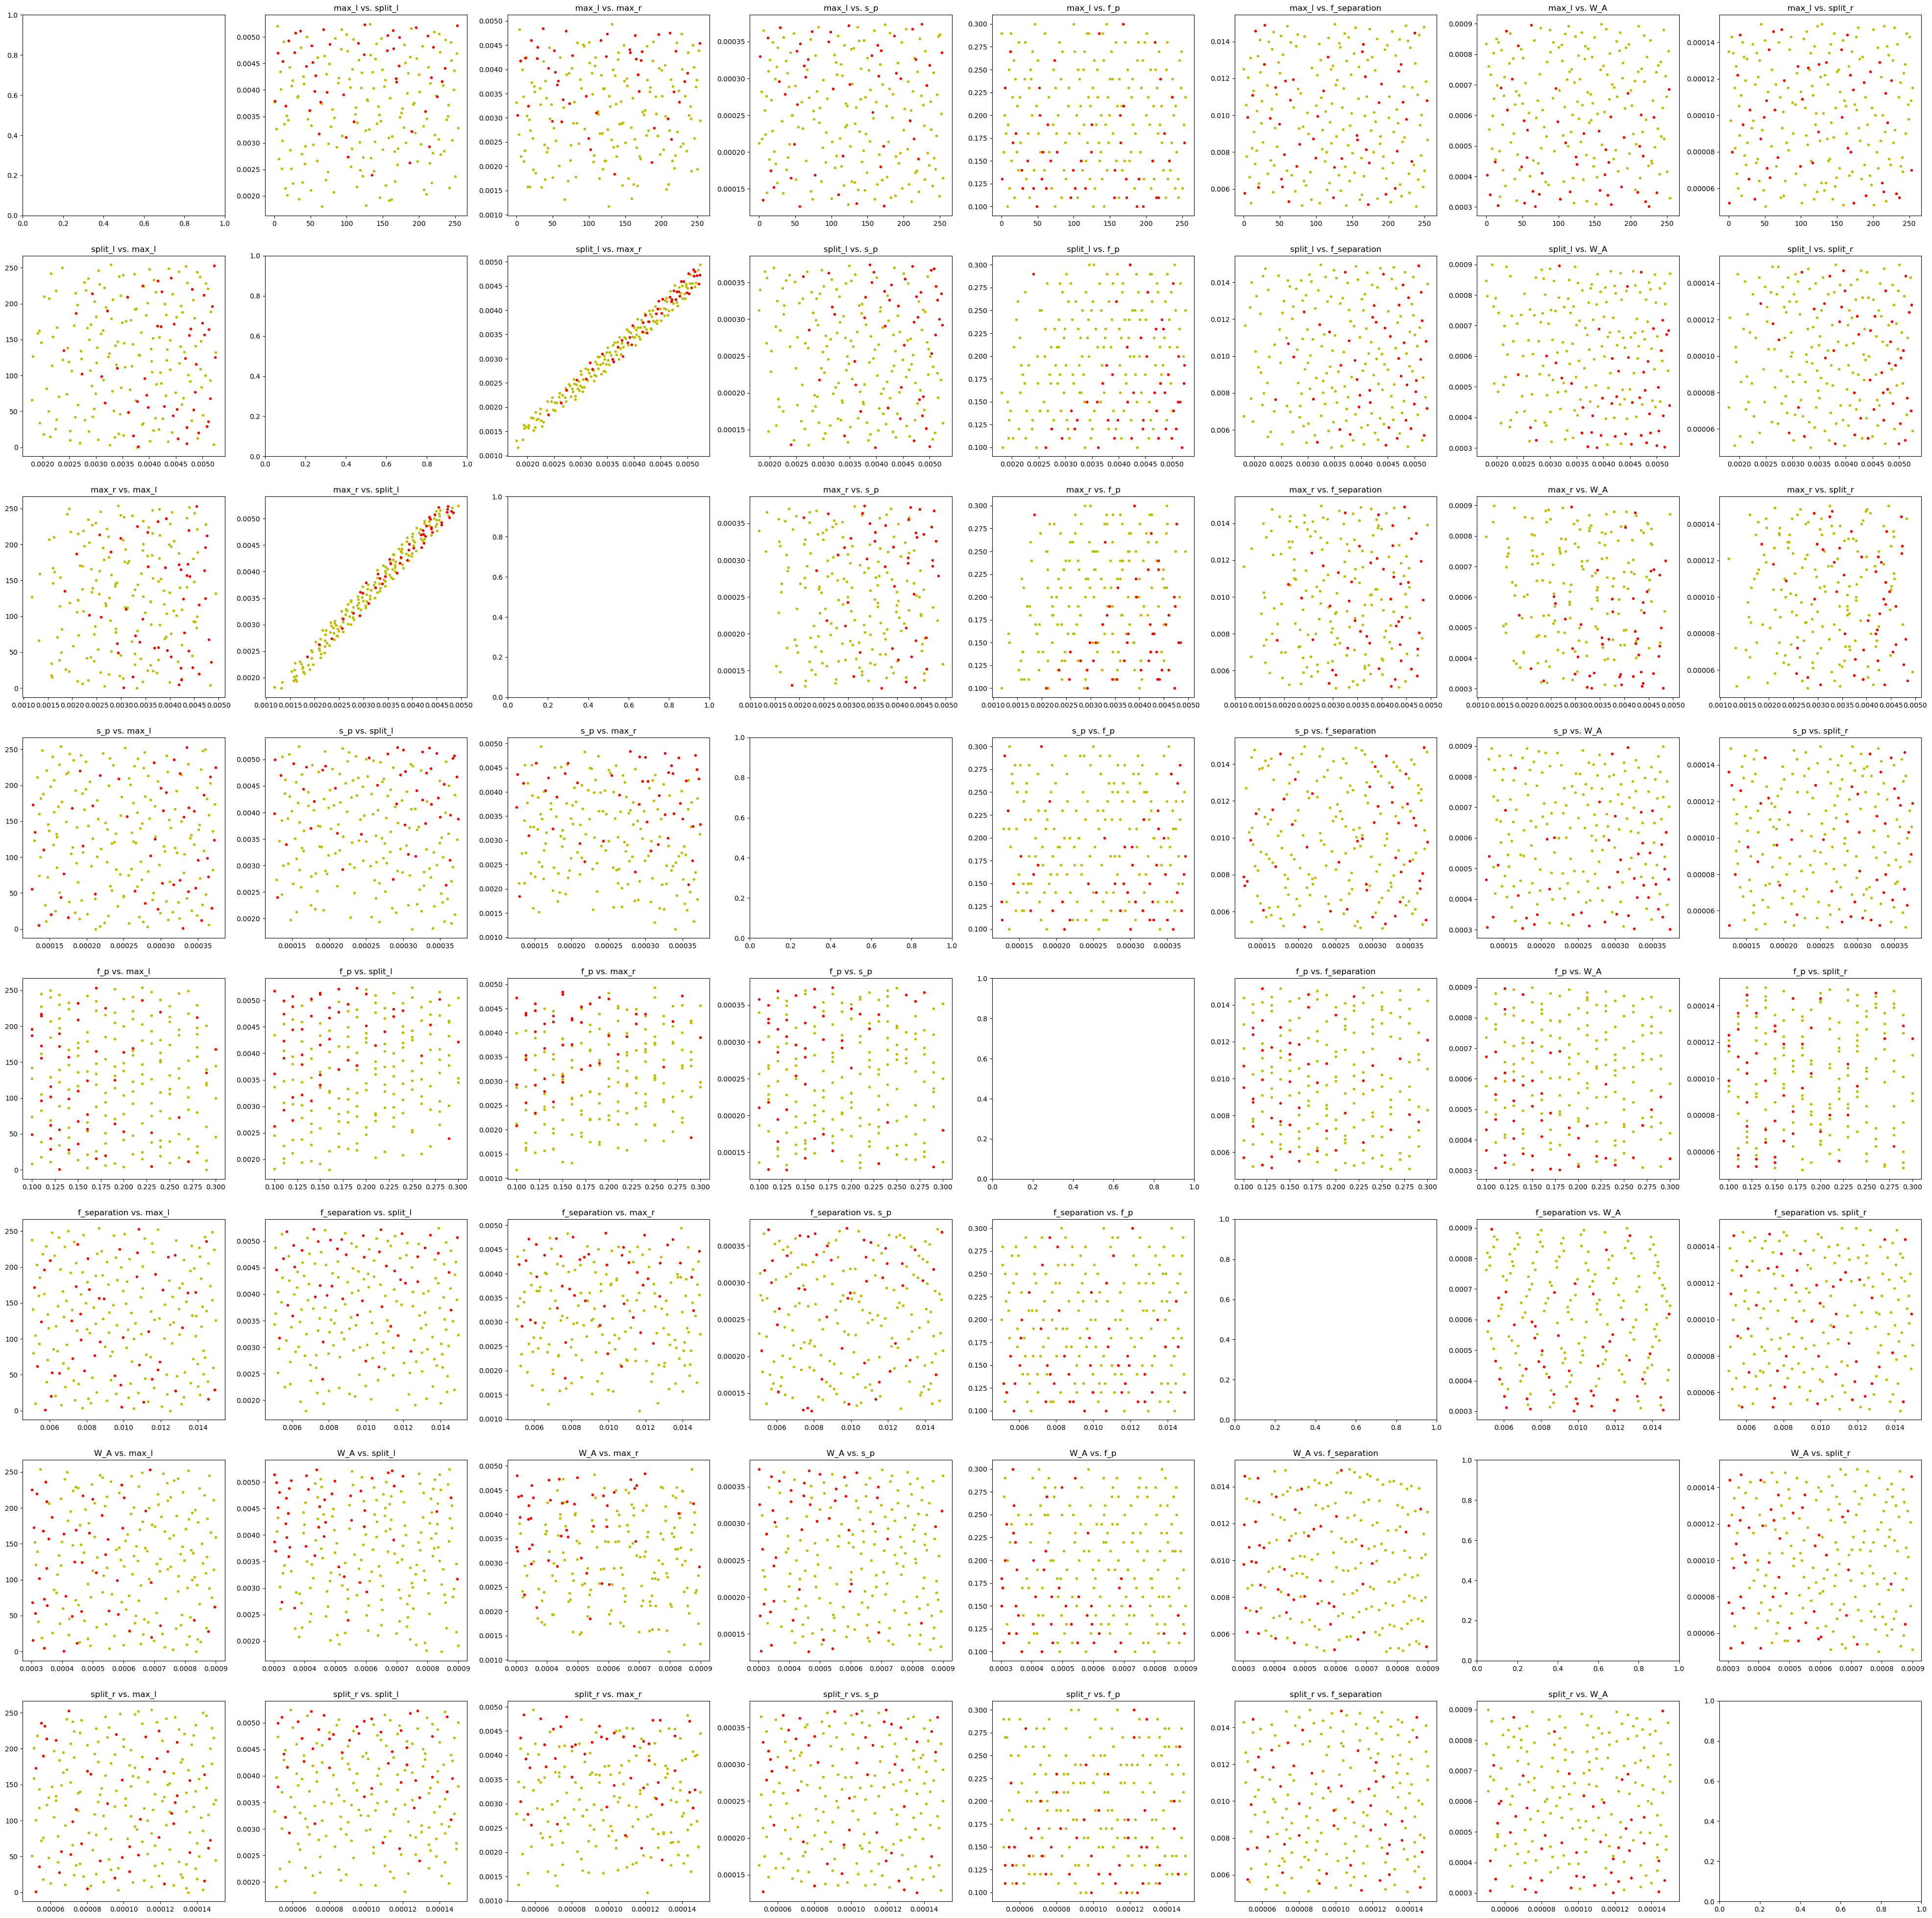

In [26]:
fig1, ax1 = plt.subplots(8, 8, figsize = (50, 50))
for i in range(8):
    for j in range(8):
        if i!=j:
            for p in good_params.values():
                ax1[i, j].plot(float(p[i]), float(p[j]), 'y.')
            for p in bad_params.values():
                ax1[i, j].plot(float(p[i]), float(p[j]), 'r.')

            ax1[i, j].set_title(params[i] + ' vs. ' + params[j])
            # ax1[i, j].set_xscale('log')
            # ax1[i, j].set_yscale('log')

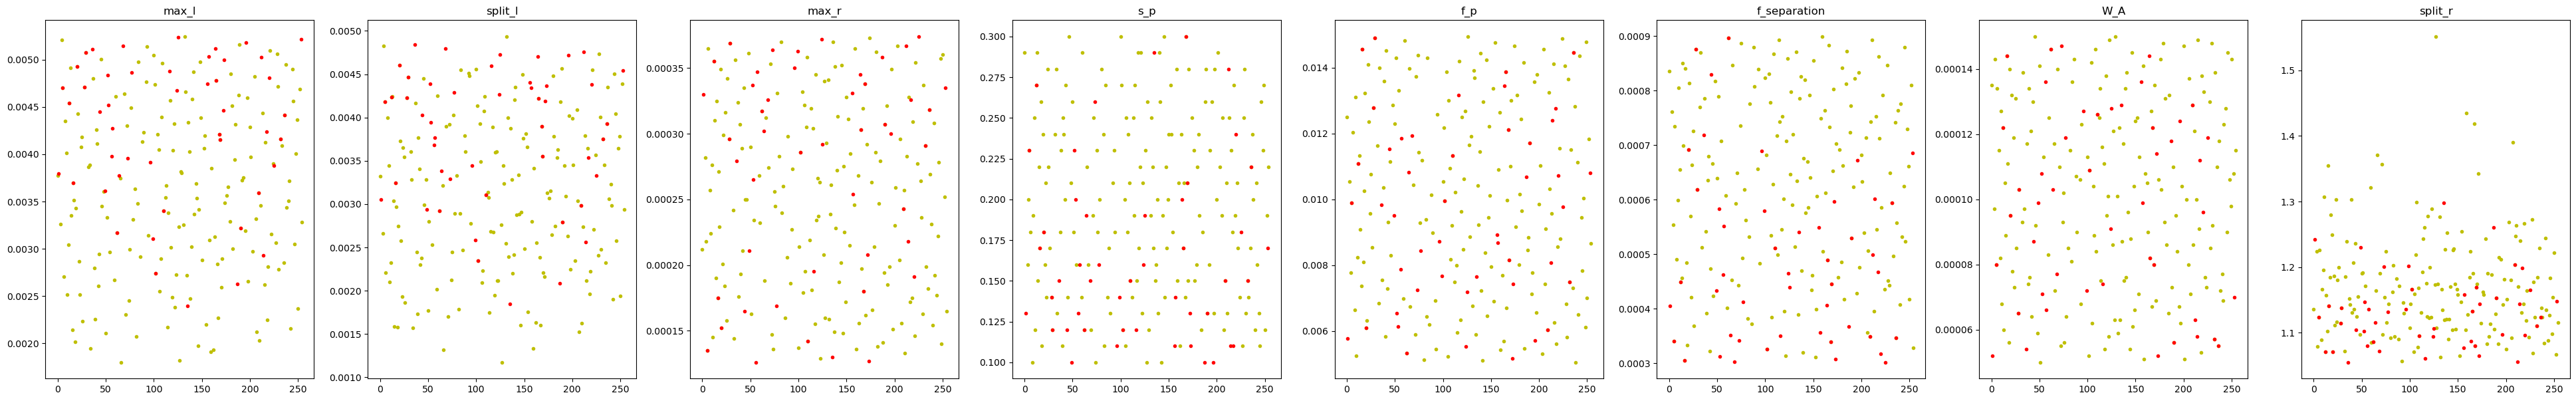

In [37]:
fig2, ax2 = plt.subplots(1, 8, figsize = (49, 7))
for par in np.arange(len(params)): 
    for run in good_params.keys():
        p = good_params[run]
        ax2[par].plot(run, float(p[par + 1]), 'y.')
    for run in bad_params.keys():
        p = bad_params[run]
        ax2[par].plot(run, float(p[par + 1]), 'r.') 
    ax2[par].set_title(params[par])